In [26]:
# Cell 1 — Imports
import numpy as np
import pandas as pd
import xarray as xr
import sys
import matplotlib.pyplot as plt
from pathlib import Path
import glob
sys.path.append(str(Path("../src").resolve()))
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.align import align_to_reference_time

## WHICH DAY /DATASET

In [27]:
EPOCH = pd.Timestamp("2001-01-01")

RAW_W  = Path("../data/raw/pallas/20260925_pallasjarvi_rpg-fmcw-94_delft")
RAW_KA = Path("../data/raw/pallas/20260925_pallasjarvi_rpg-fmcw-35_delft")
KA_CLOUDNET_FILE = "../data/raw/pallas/20260925_pallasjarvi_rpg-fmcw-35_delft.nc"   # only for the site altitude
MWR_FILE = "../data/raw/pallas/20260925_pallasjarvi_hatpro-multi_T_h.nc"

KEEP_PROGRAMS = ("P02", "P07")              # chirp programme(s) to use -> check the table below
RANGE_MATCHING_METHOD = "interpolation"
Processed_Dataset = f"20260925_pallas_raw_{'_'.join(KEEP_PROGRAMS)}_CLARA"   # new folder, old results stay

def file_table(folder):
    """One row per raw file: frequency, programme, time span, gates and gate spacing per chirp."""
    rows = []
    for f in sorted(folder.glob("*ZEN*.LV1.nc")):          # also matches the 'ZEN (1).LV1.nc' Ka names
        with xr.open_dataset(f) as d:
            t = EPOCH + pd.to_timedelta(d["Time"].values, unit="s")
            chirps = range(1, d.sizes["Chirp"] + 1)
            rows.append({"file": f.name, "program": f.name.split("_")[3],
                         "freq_GHz": round(float(np.ravel(d["Freq"].values)[0]), 1),
                         "start": f"{t[0]:%H:%M:%S}", "end": f"{t[-1]:%H:%M:%S}", "profiles": t.size,
                         "gates": tuple(d[f"C{c}Range"].size for c in chirps),
                         "spacing_m": tuple(round(float(np.median(np.diff(d[f"C{c}Range"].values))), 1)
                                            for c in chirps)})
    return pd.DataFrame(rows)

files_w, files_ka = file_table(RAW_W), file_table(RAW_KA)
print(files_w.to_string(index=False)); print(files_ka.to_string(index=False))

                               file program  freq_GHz    start      end  profiles          gates          spacing_m
pallas_260925_005434_P02_ZEN.LV1.nc     P02      94.0 00:54:34 01:04:23       526 (74, 134, 234) (14.9, 13.5, 34.1)
pallas_260925_010919_P02_ZEN.LV1.nc     P02      94.0 01:09:19 01:18:57       517 (74, 134, 234) (14.9, 13.5, 34.1)
pallas_260925_012810_P02_ZEN.LV1.nc     P02      94.0 01:28:10 01:37:59       527 (74, 134, 234) (14.9, 13.5, 34.1)
pallas_260925_014255_P02_ZEN.LV1.nc     P02      94.0 01:42:55 01:52:34       518 (74, 134, 234) (14.9, 13.5, 34.1)
pallas_260925_020145_P02_ZEN.LV1.nc     P02      94.0 02:01:45 02:11:35       527 (74, 134, 234) (14.9, 13.5, 34.1)
pallas_260925_021633_P02_ZEN.LV1.nc     P02      94.0 02:16:33 02:26:11       517 (74, 134, 234) (14.9, 13.5, 34.1)
pallas_260925_023524_P02_ZEN.LV1.nc     P02      94.0 02:35:24 02:45:14       527 (74, 134, 234) (14.9, 13.5, 34.1)
pallas_260925_025010_P02_ZEN.LV1.nc     P02      94.0 02:50:10 02:59:48 

Load Both Radars

In [28]:
def load_rpg(files, keep_extra=()):
    wanted = {f"C{c}{v}" for c in (1, 2, 3) for v in ("ZE", "MeanVel", "Range")}
    wanted |= {"Time", "Timems", "LWP", "SurfPres"} | set(keep_extra)
    with xr.open_dataset(files[0]) as probe:
        drop = sorted(set(probe.variables) - wanted)

    def add_program(d):                     # label every profile with its programme (from the file name)
        prog = Path(d.encoding["source"]).name.split("_")[3]
        return d.assign(program=("Time", np.full(d.sizes["Time"], prog)))

    ds = xr.open_mfdataset(files, combine="by_coords", join="exact", data_vars="all",
                           drop_variables=drop, chunks={}, preprocess=add_program)
    seconds = ds["Time"].values + (ds["Timems"].values / 1000 if "Timems" in ds else 0)
    ds = ds.assign_coords(Time=("Time", EPOCH + pd.to_timedelta(seconds, unit="s")))
    return drop_duplicate_times(ds)

sel_w  = files_w[files_w.program.isin(KEEP_PROGRAMS)]
sel_ka = files_ka[files_ka.program.isin(KEEP_PROGRAMS)]
for name, sel, freq in [("W", sel_w, 94), ("Ka", sel_ka, 35)]:
    assert len(sel), f"no {name} files for {KEEP_PROGRAMS}"
    assert np.allclose(sel.freq_GHz, freq, atol=1), f"{name} folder contains a file of the other radar"
    assert sel.gates.nunique() == 1, f"{name}: these programmes have different range grids - keep only one"

EXTRA = ("Freq", "RangeRes", "SeqIntTime", "AvgNum", "DoppLen", "MaxVel")
ds_w  = load_rpg([RAW_W  / f for f in sel_w.file],  EXTRA)
ds_ka = load_rpg([RAW_KA / f for f in sel_ka.file], EXTRA)

# Cell 3 - reflectivities and velocities, chirps merged (as at Cabauw)
ze_w,  ze_ka  = get_reflectivity(ds_w), get_reflectivity(ds_ka)
vel_w  = combine_chirps(ds_w,  var_prefix="MeanVel")
vel_ka = combine_chirps(ds_ka, var_prefix="MeanVel")

# checks
print("time W :", ds_w.Time.values[[0, -1]], "\ntime Ka:", ds_ka.Time.values[[0, -1]])
print("gate spacings Ka:", np.unique(np.round(np.diff(ze_ka["range"].values), 1)))
print("median in-cloud v_Ka:", np.nanmedian(vel_ka.where(ze_ka > -30).sel(range=slice(200, 2000)).values),
      "(Cloudnet files: about -0.3, down = negative)")
print("LWP min/max:", np.nanmin(ds_w["LWP"].values), np.nanmax(ds_w["LWP"].values))

time W : ['2026-09-25T00:54:34.314000010' '2026-09-25T11:11:57.090999961'] 
time Ka: ['2026-09-25T00:54:34.314000010' '2026-09-25T11:11:57.090999961']
gate spacings Ka: [ 9.  13.5 14.9 34.1 35.2]
median in-cloud v_Ka: -0.14086607 (Cloudnet files: about -0.3, down = negative)
LWP min/max: 14.757388 225.65976


In [29]:
for v in ["SeqIntTime", "AvgNum", "DoppLen"]:
    print(f"{v:12s} {np.unique(ds_ka[v].values, axis=0)}")

SeqIntTime   [[0.45789346 0.36631477 0.18315738]
 [0.9157869  0.73262954 0.36631477]]
AvgNum       [[4096 4096 2048]
 [8192 8192 4096]]
DoppLen      [[256 256 128]
 [512 512 256]]


## Radar seperation and beam mismatch

In [30]:
import numpy as np
import glob

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6_371_000.0
    p1, p2 = np.radians([lat1, lat2])
    a = (np.sin((p2-p1)/2)**2
         + np.cos(p1)*np.cos(p2)*np.sin(np.radians(lon2-lon1)/2)**2)
    return 2*R*np.arcsin(np.sqrt(a))


def beam_overlap(d, hpbw_a, hpbw_b, heights):
    """Fractional area overlap of two circular footprints separated by d."""
    h = np.asarray(heights, float)
    ra = h * np.tan(np.radians(hpbw_a)/2)
    rb = h * np.tan(np.radians(hpbw_b)/2)
    frac = np.zeros_like(h)
    for i, (R1, R2) in enumerate(zip(ra, rb)):
        if d >= R1 + R2:
            frac[i] = 0.0
        elif d <= abs(R1 - R2):
            frac[i] = 1.0
        else:
            a1 = np.arccos((d**2 + R1**2 - R2**2)/(2*d*R1))
            a2 = np.arccos((d**2 + R2**2 - R1**2)/(2*d*R2))
            area = (R1**2*(a1 - np.sin(2*a1)/2) + R2**2*(a2 - np.sin(2*a2)/2))
            frac[i] = area / (np.pi * min(R1, R2)**2)
    return 2*ra, 2*rb, frac



with xr.open_dataset(RAW_KA / sel_ka.file.iloc[0]) as a, xr.open_dataset(RAW_W / sel_w.file.iloc[0]) as b:
    first = lambda d, v: float(np.ravel(d[v].values)[0])
    lat_ka, lon_ka, hpbw_ka = first(a, "GPSLat"), first(a, "GPSLon"), first(a, "HPBW")
    lat_w,  lon_w,  hpbw_w  = first(b, "GPSLat"), first(b, "GPSLon"), first(b, "HPBW")

sep = haversine_m(lat_ka, lon_ka, lat_w, lon_w)
print(f"separation      : {sep:.1f} m")
print(f"HPBW Ka / W     : {hpbw_ka:.3f} / {hpbw_w:.3f} deg")

hs = np.array([500., 750., 1000., 1400., 2000.])
Dka, Dw, frac = beam_overlap(sep, hpbw_ka, hpbw_w, hs)
for h, a, b, f in zip(hs, Dka, Dw, frac):
    print(f"  h={h:5.0f} m: beams {a:5.1f} / {b:5.1f} m | "
          f"separation {sep/(0.5*(a+b)):5.2f} beamwidths | overlap {f:.2f}")

separation      : 0.0 m
HPBW Ka / W     : 0.840 / 0.550 deg
  h=  500 m: beams   7.3 /   4.8 m | separation  0.00 beamwidths | overlap 1.00
  h=  750 m: beams  11.0 /   7.2 m | separation  0.00 beamwidths | overlap 1.00
  h= 1000 m: beams  14.7 /   9.6 m | separation  0.00 beamwidths | overlap 1.00
  h= 1400 m: beams  20.5 /  13.4 m | separation  0.00 beamwidths | overlap 1.00
  h= 2000 m: beams  29.3 /  19.2 m | separation  0.00 beamwidths | overlap 1.00


In [31]:
print(f"Ka: {lat_ka:.7f}, {lon_ka:.7f}")
print(f"W : {lat_w:.7f}, {lon_w:.7f}")

Ka: 68.0226898, 24.1594963
W : 68.0226898, 24.1594963


In [32]:
print(ds_ka.variables)

Frozen({'Freq': <xarray.Variable (Time: 17229)> Size: 69kB
array([35., 35., 35., ..., 35., 35., 35.], shape=(17229,), dtype=float32)
Attributes:
    Name:     Carrier frequency of the radar active channel
    Units:    GHz, 'DoppLen': <xarray.Variable (Time: 17229, Chirp: 3)> Size: 207kB
dask.array<getitem, shape=(17229, 3), dtype=int32, chunksize=(3478, 3), chunktype=numpy.ndarray>
Attributes:
    Name:     Number of spectral lines in Doppler spectra, 'AvgNum': <xarray.Variable (Time: 17229, Chirp: 3)> Size: 207kB
dask.array<getitem, shape=(17229, 3), dtype=int32, chunksize=(3478, 3), chunktype=numpy.ndarray>
Attributes:
    Name:     Number of chirps averaged (coherently and non-coherently) for a..., 'SeqIntTime': <xarray.Variable (Time: 17229, Chirp: 3)> Size: 207kB
dask.array<getitem, shape=(17229, 3), dtype=float32, chunksize=(3478, 3), chunktype=numpy.ndarray>
Attributes:
    Name:     Effective integration time
    Units:    s, 'RangeRes': <xarray.Variable (Time: 17229, Chirp: 3

Reflectivities

Ranges and Time Coverage

In [33]:
# Cell 4 — Inspect ranges & time coverage  ← KEEP, condensed
print(f"W : {ze_w['range'].values[0]:.1f} → {ze_w['range'].values[-1]:.1f} m  ({ze_w.sizes['range']} gates)")
print(f"Ka: {ze_ka['range'].values[0]:.1f} → {ze_ka['range'].values[-1]:.1f} m  ({ze_ka.sizes['range']} gates)")
identical = (ze_w.sizes["range"] == ze_ka.sizes["range"]) and np.allclose(ze_w["range"].values, ze_ka["range"].values)
print(f"Ranges identical: {identical}")

# Time coverage
print(f"\nW  : {ze_w.Time.values[0]}  →  {ze_w.Time.values[-1]}  ({ze_w.sizes['Time']} samples)")
print(f"Ka : {ze_ka.Time.values[0]}  →  {ze_ka.Time.values[-1]}  ({ze_ka.sizes['Time']} samples)")

# Temporal resolution
dt_ka = (ze_ka.Time.diff("Time") / np.timedelta64(1,"s")).median().values
dt_w  = (ze_w.Time.diff("Time")  / np.timedelta64(1,"s")).median().values
print(f"\nMedian Δt  W={dt_w:.1f}s   Ka={dt_ka:.1f}s")


W : 104.3 → 10970.7 m  (442 gates)
Ka: 104.3 → 10970.7 m  (442 gates)
Ranges identical: True

W  : 2026-09-25T00:54:34.314000010  →  2026-09-25T11:11:57.090999961  (17229 samples)
Ka : 2026-09-25T00:54:34.314000010  →  2026-09-25T11:11:57.090999961  (17229 samples)

Median Δt  W=1.1s   Ka=1.1s


==================================================================================================================================================

ALIGN TIME

==================================================================================================================================================

In [34]:
# Cell 5 — Common time grid  --> If it is more then a little part that is missing for the time steps

# ze_w_c = align_to_reference_time(
    #da_ref=ze_ka,
    #da_target=ze_w,
    #method="nearest"
#)

#ze_ka_c = ze_ka

In [35]:
# Cell 6 — Range alignment (only if not identical)
#if not identical:
 # ze_ka_c = ze_ka_c.interp(range=ze_w_c["range"])

In [36]:
print(len(ze_w.Time))
print(len(ze_ka.Time))

17229
17229


In [37]:
# =====================================================================================
# CELL 18 - MATCH THE TWO RADARS IN TIME              (identical in both runs)
# Ka is the reference clock: every Ka profile gets the W profile that is closest in time.
# Replaces your current step-18 cell completely.
# =====================================================================================

# Typical time between two consecutive profiles of each radar.
# .diff() = difference between neighbouring time stamps; the median ignores the few long gaps.
time_step_w  = pd.Series(ds_w.Time.values).diff().median()
time_step_ka = pd.Series(ds_ka.Time.values).diff().median()

# Largest time difference that still counts as "the same moment": half the slower radar's time step.
# (My choice, not from a paper: within half a step a Ka profile can only be paired with the W profile
#  whose own sampling interval it falls into - never with the one before or after.)
time_tolerance = max(time_step_w, time_step_ka) / 2

# For every Ka time stamp: position of the nearest W time stamp, or -1 if no W profile lies within
# the tolerance (W gap, radar off). pandas does this search: DatetimeIndex.get_indexer(method="nearest").
nearest_w_index = pd.DatetimeIndex(ds_w.Time.values).get_indexer(
    ds_ka.Time.values, method="nearest", tolerance=time_tolerance)

has_w_partner = nearest_w_index >= 0                  # True for Ka profiles that found a W partner
common_times  = ds_ka.Time.values[has_w_partner]      # the time axis both radars share from now on


def w_at_common_times(w_variable):
    """Any W variable with a Time axis -> for every common time the nearest W profile,
    relabelled with the Ka time stamp, so W and Ka end up with identical time labels."""
    nearest_w = w_variable.sel(Time=common_times, method="nearest", tolerance=time_tolerance)
    return nearest_w.assign_coords(Time=common_times)


# Quality check of the pairing: the real time difference between paired profiles, in seconds.
time_offset_s = (ds_w.Time.values[nearest_w_index[has_w_partner]] - common_times) / np.timedelta64(1, "s")

print(f"W : {ds_w.sizes['Time']} profiles, time step {time_step_w.total_seconds():.1f} s")
print(f"Ka: {ds_ka.sizes['Time']} profiles, time step {time_step_ka.total_seconds():.1f} s")
print(f"common times: {common_times.size} (tolerance {time_tolerance.total_seconds():.1f} s) | "
      f"time offset median {np.median(np.abs(time_offset_s)):.2f} s, max {np.abs(time_offset_s).max():.2f} s")

W : 17229 profiles, time step 1.1 s
Ka: 17229 profiles, time step 1.1 s
common times: 17229 (tolerance 0.6 s) | time offset median 0.00 s, max 0.00 s


In [38]:
# =====================================================================================
# CELL 20a - RANGE-MATCHING TOOLS                    (identical in both runs; new cell after cell 18)
# Both methods do the same thing: every value on the common grid is a WEIGHTED AVERAGE of one
# radar's own gates. They only differ in the weights:
#   interpolation -> the two neighbouring gates, weighted by distance
#   gaussian      -> a bell curve over several gates (Williams & Vivekanandan 2007)
# The weights live in a "weight table": one row per common gate, one column per radar gate.
# =====================================================================================

def linear_interpolation_weights(source_range, target_range):
    """Weight table for linear interpolation from a radar's own gates (source_range) to the
    common gates (target_range). Each row has at most two non-zero weights; they add up to 1."""
    n_source_gates = source_range.size
    # Index of the first radar gate at or above each target height (binary search, numpy.searchsorted).
    upper_gate = np.searchsorted(source_range, target_range, side="left")
    upper_gate = np.clip(upper_gate, 1, n_source_gates - 1)       # always keep a valid pair below/above
    lower_gate = upper_gate - 1
    # Where the target lies between the two gates: 0 = exactly on the lower gate, 1 = on the upper gate.
    fraction = (target_range - source_range[lower_gate]) / (source_range[upper_gate] - source_range[lower_gate])
    weight_table = np.zeros((target_range.size, n_source_gates))
    # Only targets inside the radar's own height coverage get weights (no extrapolation).
    inside = (target_range >= source_range[0]) & (target_range <= source_range[-1])
    rows = np.flatnonzero(inside)
    weight_table[rows, lower_gate[inside]] += 1.0 - fraction[inside]   # the closer gate gets the larger weight
    weight_table[rows, upper_gate[inside]] += fraction[inside]
    return weight_table      # a target exactly on a radar gate gets weight 1 there -> value unchanged


def apply_range_weights(field_linear, weight_table, target_range, min_valid_weight_fraction=0.5):
    """Weighted average along range, for all profiles at once:
    result[t, i] = sum_j weight[i, j] * field[t, j] / sum_j weight[i, j]   (only gates j that have data)."""
    values = field_linear.transpose("Time", "range").values      # numpy array (time, radar gates)
    has_data = np.isfinite(values)                                # False where Cloudnet masked the gate (no echo)
    # Matrix product = for every profile and every common gate: the sum of weight x value.
    weighted_sum = np.where(has_data, values, 0.0) @ weight_table.T
    valid_weight = has_data.astype(float) @ weight_table.T        # sum of the weights of the gates WITH data
    total_weight = weight_table.sum(axis=1)                       # sum of all weights in a row
    with np.errstate(invalid="ignore", divide="ignore"):
        result = weighted_sum / valid_weight                      # weighted mean over the gates with data
    # If less than half of a row's weight has data (cloud edge), don't invent a value -> NaN.
    # (My choice. Same rule in both methods, so cloud edges are treated identically in the comparison.)
    result[valid_weight < min_valid_weight_fraction * total_weight] = np.nan
    return xr.DataArray(result, dims=("Time", "range"),
                        coords={"Time": field_linear["Time"].values, "range": target_range})


def match_reflectivity_and_velocity(reflectivity_dbz, doppler_velocity, weight_table, target_range):
    """Put one radar's reflectivity and Doppler velocity onto the common grid with a weight table."""
    # Reflectivity adds up in linear units (mm^6 m^-3 = sum of D^6 per volume), not in dB. Averaging
    # dB values gives a biased (too low) value, so: dBZ -> linear -> weighted average -> dBZ.
    z_linear = 10.0 ** (reflectivity_dbz / 10.0)
    reflectivity_common_dbz = 10.0 * np.log10(apply_range_weights(z_linear, weight_table, target_range))
    # Mean Doppler velocity = reflectivity-weighted mean velocity of a volume (first moment of the Doppler
    # spectrum). Combining gates = adding their spectra, so the velocities must be weighted with Z as well:
    # v_common = average(Z * v) / average(Z), using only gates that have a velocity.
    z_where_velocity = z_linear.where(doppler_velocity.notnull())
    velocity_common = (apply_range_weights(z_where_velocity * doppler_velocity, weight_table, target_range)
                       / apply_range_weights(z_where_velocity, weight_table, target_range))
    return reflectivity_common_dbz, velocity_common


def effective_number_of_gates(weight_table):
    """(sum w)^2 / sum(w^2) = how many independent radar gates one common gate is worth
    (Kish's effective sample size). 1 = a single gate. If the radar's gates are independent,
    the noise of the common gate is reduced by sqrt(this number)."""
    with np.errstate(invalid="ignore", divide="ignore"):
        return weight_table.sum(axis=1) ** 2 / (weight_table ** 2).sum(axis=1)

In [39]:
# =====================================================================================
# CELL 20b - RANGE MATCHING BY LINEAR INTERPOLATION   (run 1)
# Common grid = the Ka gates. Ka keeps its own values; W is interpolated onto the Ka gates.
# Replaces your current step-20 cell AND steps 35-37 (the velocities are matched here now).
# =====================================================================================
assert RANGE_MATCHING_METHOD == "interpolation", "this is the interpolation cell - check step 2"

range_ka = ze_ka["range"].values.astype(float)     # Ka gate heights above the radar [m]
range_w  = ze_w["range"].values.astype(float)      # W gate heights above the radar [m]

# Common grid: every Ka gate inside the height range that W also covers (W is never extrapolated).
common_range = range_ka[(range_ka >= range_w[0]) & (range_ka <= range_w[-1])]

weights_ka = linear_interpolation_weights(range_ka, common_range)   # each row: weight 1 on its own Ka gate
weights_w  = linear_interpolation_weights(range_w,  common_range)   # each row: the two W gates around it

ze_ka_c, MeanVel_Ka_c = match_reflectivity_and_velocity(
    ze_ka.sel(Time=common_times), vel_ka.sel(Time=common_times), weights_ka, common_range)
ze_w_c, MeanVel_W_c = match_reflectivity_and_velocity(
    w_at_common_times(ze_w), w_at_common_times(vel_w), weights_w, common_range)

n_eff_w = effective_number_of_gates(weights_w)
print(f"common grid: {common_range.size} Ka gates, {common_range[0]:.0f}-{common_range[-1]:.0f} m")
print(f"W gates per common gate: {np.nanmin(n_eff_w):.2f} to {np.nanmax(n_eff_w):.2f} "
      "(never more than 2 -> interpolation adds no independent W information)")
print(f"after matching: Ka {ze_ka_c.shape}, W {ze_w_c.shape}")

common grid: 442 Ka gates, 104-10971 m
W gates per common gate: 1.00 to 1.00 (never more than 2 -> interpolation adds no independent W information)
after matching: Ka (17229, 442), W (17229, 442)


In [40]:
# Cell 7 — Verify
print(f"After alignment: W={ze_w_c.shape}, Ka={ze_ka_c.shape}")
assert ze_w_c.shape == ze_ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

After alignment: W=(17229, 442), Ka=(17229, 442)
✅ Aligned on common (time, range) grid


==================================================================================================================================================

PLOT

==================================================================================================================================================

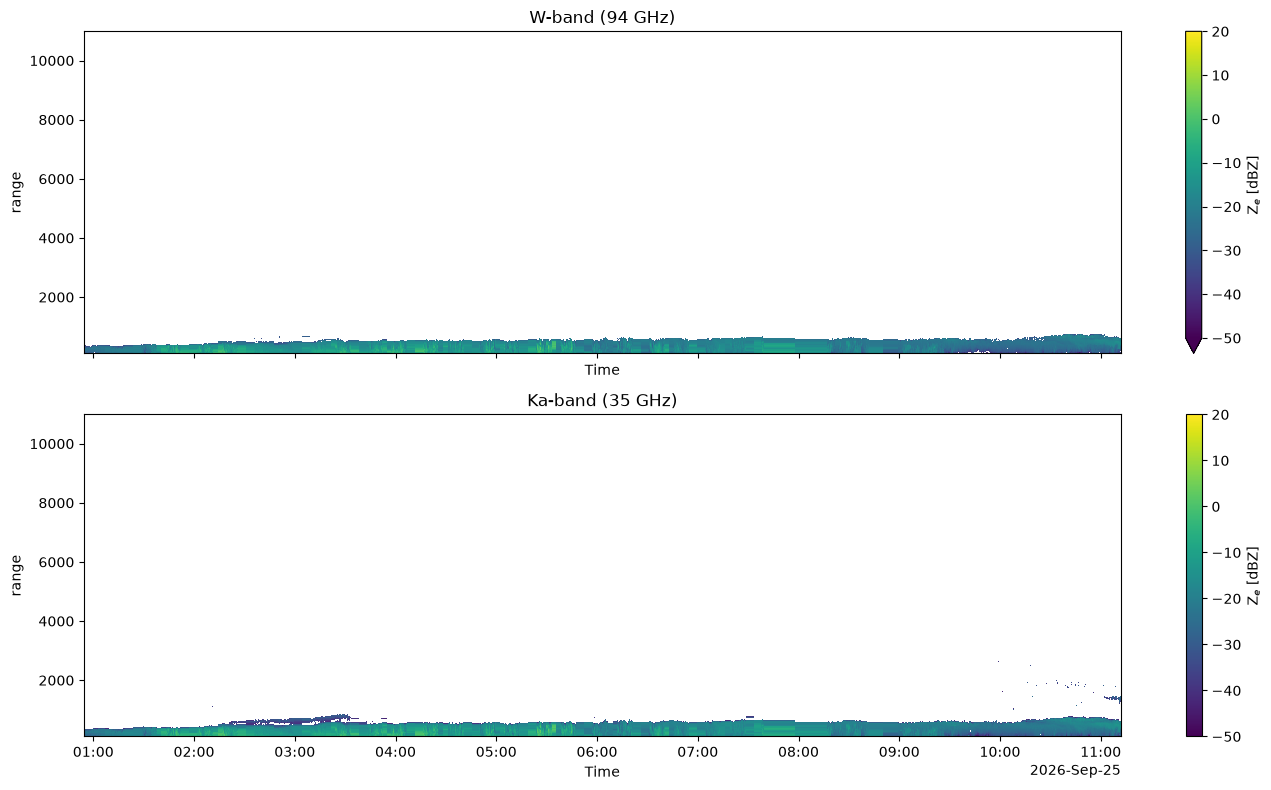

In [41]:
# Cell 8 — Side-by-side plot
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
ze_w_c.plot(x="Time", y="range", ax=axes[0], cmap="viridis", vmin=-50, vmax=20, cbar_kwargs={"label": "Z$_e$ [dBZ]"})
axes[0].set_title("W-band (94 GHz)")
ze_ka_c.plot(x="Time", y="range", ax=axes[1], cmap="viridis", vmin=-50, vmax=20, cbar_kwargs={"label": "Z$_e$ [dBZ]"})
axes[1].set_title("Ka-band (35 GHz)")
plt.tight_layout()
plt.show()

(array([1.0000e+00, 1.0000e+00, 4.0000e+00, 6.6000e+01, 1.2200e+02,
        2.0300e+02, 3.1900e+02, 4.7800e+02, 6.8200e+02, 8.7200e+02,
        9.8200e+02, 1.1540e+03, 1.3030e+03, 1.3360e+03, 1.4640e+03,
        1.5980e+03, 1.6480e+03, 1.8280e+03, 1.8950e+03, 2.0100e+03,
        2.0870e+03, 2.2930e+03, 2.3400e+03, 2.4920e+03, 2.7590e+03,
        2.8750e+03, 2.9540e+03, 3.3280e+03, 3.5140e+03, 3.4290e+03,
        3.7170e+03, 3.7410e+03, 3.8170e+03, 3.8940e+03, 4.1740e+03,
        4.6140e+03, 4.9460e+03, 5.4880e+03, 6.0800e+03, 6.4300e+03,
        7.1050e+03, 7.7760e+03, 8.4180e+03, 9.7920e+03, 1.1368e+04,
        1.3557e+04, 1.5923e+04, 1.7495e+04, 1.7950e+04, 1.8222e+04,
        1.8060e+04, 1.7748e+04, 1.8224e+04, 1.8242e+04, 1.7850e+04,
        1.7285e+04, 1.7499e+04, 1.8057e+04, 1.6541e+04, 1.4980e+04,
        1.3642e+04, 1.2311e+04, 1.2005e+04, 1.1431e+04, 1.0712e+04,
        1.0304e+04, 9.9470e+03, 9.6070e+03, 8.8000e+03, 8.2590e+03,
        7.8970e+03, 7.5020e+03, 7.0470e+03, 6.52

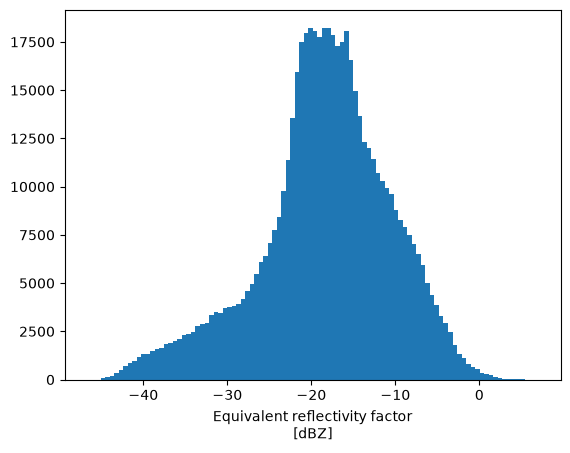

In [42]:
ze_ka.plot.hist(bins=100)

TEMPERATURE

==================================================================================================================================================

The T Profile Values are interpolated onto the Range grid. First we have to get the altitudes for the Temperature Profile in T_Alts, because Temperature Profile T_Prof only has Indices 1,2,3,.... Afterwards T_Prof uses T_Alts Altitudes and then the Values are interpolated onto the range grid

==================================================================================================================================================

In [43]:
mwr = xr.open_dataset(MWR_FILE)

In [44]:
mwr

<xarray.Dataset> Size: 226kB
Dimensions:                           (time: 144, height: 94)
Coordinates:
  * time                              (time) datetime64[ns] 1kB 2026-09-25T00...
  * height                            (height) float32 376B 275.0 ... 1.028e+04
Data variables: (12/13)
    latitude                          (time) float32 576B ...
    longitude                         (time) float32 576B ...
    altitude                          (time) float32 576B ...
    quality_flag                      (time) float64 1kB ...
    quality_flag_status               (time) float64 1kB ...
    elevation_angle                   (time) float32 576B ...
    ...                                ...
    temperature                       (time, height) float32 54kB ...
    temperature_quality_flag          (time) float64 1kB ...
    temperature_quality_flag_status   (time) float64 1kB ...
    relative_humidity                 (time, height) float32 54kB ...
    potential_temperature             (time, height) float32 54kB ...
    equivalent_potential_temperature  (time, height) float32 54kB ...
Attributes: (12/16)
    year:                         2026
    month:                        09
    day:                          25
    location:                     Pallasjärvi
    source:                       RPG-Radiometer Physics HATPRO\nVaisala CL31
    Conventions:                  CF-1.8
    ...                           ...
    history:                      2026-09-26 12:13:16 +00:00 - MWR multiple-p...
    source_file_uuids:            783a1c24-8390-40cb-b7c6-4564f424b958
    mwrpy_version:                1.7.1
    instrument_pid:               https://hdl.handle.net/21.12132/3.46797fd61...
    pid:                          https://hdl.handle.net/21.12132/1.301582283...
    cloudnet_processing_version:  2.65.8

In [45]:
# =====================================================================================
# CELL 25 - TEMPERATURE / HUMIDITY / PRESSURE PROFILES ONTO THE RADAR GRID
# Works for any source that gives values on (time x height above sea level).
# Replaces steps 24, 25 and 28 (TProf/AHProf no longer exist in the Cloudnet radar files).
# =====================================================================================

SITE_ALT_M = float(xr.open_dataset(KA_CLOUDNET_FILE)["altitude"].median())

def profile_to_common_grid(profile_values, profile_times, profile_heights_asl, max_time_gap_minutes=60):
    """(source times x source heights) -> (common_times x common_range):
    first interpolate every source profile in height, then in time."""
    # Height of each common gate above mean sea level. Cloudnet 'altitude' = site altitude above mean sea
    # level (CloudnetPy metadata.py); the radar points vertically, so gate height = range + altitude
    # (Cloudnet computes its own 'height' variable the same way: cloudnet_instrument.py, add_height).
    common_heights_asl = common_range + SITE_ALT_M
    values  = np.asarray(profile_values, dtype=float)                                     # (source times, levels)
    heights = np.broadcast_to(np.asarray(profile_heights_asl, dtype=float), values.shape)   # 1-D heights -> every time
    on_radar_heights = np.full((values.shape[0], common_range.size), np.nan)
    for i in range(values.shape[0]):                                  # one source profile at a time
        usable = np.isfinite(values[i]) & np.isfinite(heights[i])     # skip missing levels
        if usable.sum() < 2:
            continue                                                  # empty profile -> stays NaN
        order = np.argsort(heights[i][usable])                        # np.interp needs increasing heights
        on_radar_heights[i] = np.interp(common_heights_asl,
                                        heights[i][usable][order], values[i][usable][order],
                                        right=np.nan)                 # above the profile top: no value
                                                                      # (below the lowest level: lowest value)
    profile = xr.DataArray(on_radar_heights, dims=("profile_time", "range"),
                           coords={"profile_time": np.asarray(profile_times).astype("datetime64[ns]"),
                                   "range": common_range})
    # NEW 1: drop source profiles without any value (MWR gap, rain/quality flag). Otherwise a single empty
    # profile makes every radar time between its two neighbours NaN; now the interpolation bridges it.
    profile = profile.dropna("profile_time", how="all")
    common_time_axis = xr.DataArray(common_times, dims="Time", coords={"Time": common_times})
    # Between two source profiles: linear interpolation in time (as before).
    linear = profile.interp(profile_time=common_time_axis).drop_vars("profile_time")
    # NEW 2: before the first / after the last source profile, linear interpolation has nothing on one side
    # and gives NaN -> use the nearest source profile there instead.
    nearest = profile.sel(profile_time=common_time_axis, method="nearest")
    time_to_nearest_profile = np.abs(nearest["profile_time"].values - common_times)
    on_common_grid = linear.fillna(nearest.drop_vars("profile_time"))
    # NEW 3: no source profile within max_time_gap_minutes -> no value, instead of stretching one profile
    # over hours. (My choice: 60 min; temperature changes slowly, but not over a whole afternoon.)
    too_far = xr.DataArray(time_to_nearest_profile > np.timedelta64(max_time_gap_minutes, "m"),
                           dims="Time", coords={"Time": common_times})
    return on_common_grid.where(~too_far)


# ---------- OPTION A: Cloudnet CATEGORIZE file (your supervisor's suggestion) ----------
# temperature [K], pressure [Pa], q [kg/kg] on (model_time, model_height); model_height is above mean
# sea level (CloudnetPy categorize.py). These are the weather MODEL's fields, copied from the model file -
# not measurements. Don't use 'Tw': that is wet-bulb temperature.
# categorize = xr.open_dataset(CATEGORIZE_FILE)
# model_grid = dict(profile_times=categorize["model_time"].values,
#                   profile_heights_asl=categorize["model_height"].values)
# T_on_range = profile_to_common_grid(categorize["temperature"].values, **model_grid).rename("T_cloud")   # K
# pressure_pa = profile_to_common_grid(categorize["pressure"].values, **model_grid)                       # Pa
# specific_humidity = profile_to_common_grid(categorize["q"].values, **model_grid)                        # kg/kg
# # Absolute humidity = q x air density; air density = p / (R_d * T_virtual), T_virtual = T * (1 + 0.608 q).
# AH_on_range = (1000.0 * specific_humidity * pressure_pa
#                / (287.05 * T_on_range * (1 + 0.608 * specific_humidity))).rename("AH_cloud")           # g m-3
# P_cloud = (pressure_pa / 100.0).rename("P_cloud")                                                       # hPa

# ---------- OPTION B: Cloudnet MWR product (mwr-single or mwr-multi) ----------
# temperature [K] and absolute_humidity [kg m-3] on (time, height); height is above mean sea level
# (mwrpy level2/lev2_meta_nc.py, which Cloudnet uses to make these products). No pressure profile ->
# keep your barometric P_cloud cell (step 32) with this option.
mwr = xr.open_dataset(MWR_FILE)

# ---------- 1) CHECK what the file contains: names, dimensions, units, value ranges ----------
for name in ("temperature", "relative_humidity", "height", "time"):
    if name not in mwr:
        print(f"{name:18s} NOT IN FILE -> look at print(mwr) for the right name")
        continue
    variable = mwr[name]
    if variable.dtype.kind in "fi":                                   # numbers: show min and max
        value_range = f"{float(variable.min()):.2f} to {float(variable.max()):.2f}"
    else:                                                             # time stamps: show first and last
        value_range = f"{variable.values[0]} to {variable.values[-1]}"
    print(f"{name:18s} dims {variable.dims} | units {variable.attrs.get('units')!r} | "
          f"{variable.attrs.get('long_name', '')!r} | {value_range}")

# ---------- 2) TEMPERATURE -> Kelvin ----------
temperature = mwr["temperature"].transpose("time", ...)              # make sure the order is (time, height)
if float(temperature.max()) < 100:          # no air temperature is below 100 K, so values below 100 must be degC
    print("temperature looks like degC -> converting to K")
    temperature = temperature + 273.15
temperature_k = temperature.values

# ---------- 3) RELATIVE HUMIDITY -> fraction 0..1 ----------
# Cloudnet/mwrpy stores it as a fraction (units "1"); other files use %. Values above 1.5 can only be %.
relative_humidity = mwr["relative_humidity"].transpose("time", ...)
if float(relative_humidity.max()) > 1.5:
    print("relative humidity looks like % -> converting to fraction")
    relative_humidity = relative_humidity / 100.0
relative_humidity_fraction = relative_humidity.values
assert relative_humidity_fraction.shape == temperature_k.shape, "T and RH are on different grids - tell me"

# ---------- 4) RELATIVE -> ABSOLUTE HUMIDITY, on the MWR's own grid ----------
# Saturation vapour pressure over liquid water, Magnus formula (Alduchov & Eskridge 1996), T in degC -> Pa.
temperature_c = temperature_k - 273.15
saturation_vapour_pressure_pa = 611.94 * np.exp(17.625 * temperature_c / (temperature_c + 243.04))
# Relative humidity = vapour pressure / saturation vapour pressure  ->  vapour pressure:
vapour_pressure_pa = relative_humidity_fraction * saturation_vapour_pressure_pa
# Ideal gas law for water vapour: absolute humidity = e / (R_v * T), R_v = 461.5 J kg-1 K-1 -> kg m-3, x1000 -> g m-3.
# (No pressure needed for this conversion.)
absolute_humidity_g_m3 = 1000.0 * vapour_pressure_pa / (461.5 * temperature_k)

# ---------- 5) ONTO THE RADAR GRID (function from the top of this cell) ----------
# profile_to_common_grid expects heights above MEAN SEA LEVEL. If the height check above says
# "above ground", use: mwr["height"].values + float(ds_ka["altitude"].median())
mwr_grid = dict(profile_times=mwr["time"].values, profile_heights_asl=mwr["height"].values)
T_on_range  = profile_to_common_grid(temperature_k, **mwr_grid).rename("T_cloud")              # K
AH_on_range = profile_to_common_grid(absolute_humidity_g_m3, **mwr_grid).rename("AH_cloud")    # g m-3

T_on_range.attrs["units"] = "K"
AH_on_range.attrs["units"] = "g m-3"
print(f"T : {float(T_on_range.min()):.1f} to {float(T_on_range.max()):.1f} K, shape {T_on_range.shape}")
print(f"AH: {float(AH_on_range.min()):.2f} to {float(AH_on_range.max()):.2f} g m-3")

temperature        dims ('time', 'height') | units 'K' | 'Temperature' | 225.16 to 283.85
relative_humidity  dims ('time', 'height') | units '1' | 'Relative humidity' | 0.04 to 1.38
height             dims ('height',) | units 'm' | 'Height above mean sea level' | 275.00 to 10275.00
time               dims ('time',) | units None | 'Time UTC' | 2026-09-25T00:02:23.999996781 to 2026-09-25T23:52:25.996856689
T : 226.4 to 280.0 K, shape (17229, 442)
AH: 0.02 to 8.45 g m-3


In [46]:
profile_without_T = T_on_range.sel(range=slice(0, 4000)).isnull().all("range").values
print("radar profiles without T:", int(profile_without_T.sum()),
      "| from", common_times[profile_without_T][:1], "to", common_times[profile_without_T][-1:])
print("radar:", common_times[0], "->", common_times[-1])
print("MWR  :", mwr.time.values[0], "->", mwr.time.values[-1],
      "| empty MWR profiles at:", mwr.time.values[np.isnan(temperature_k).all(axis=1)])

radar profiles without T: 0 | from [] to []
radar: 2026-09-25T00:54:34.314000010 -> 2026-09-25T11:11:57.090999961
MWR  : 2026-09-25T00:02:23.999996781 -> 2026-09-25T23:52:25.996856689 | empty MWR profiles at: []


In [47]:
print(T_on_range.shape)                                # should match ze_w_c.shape
print(f"{float(T_on_range.min()):.1f} → {float(T_on_range.max()):.1f} °K")
print("NaN in T below 4 km:", int(T_on_range.sel(range=slice(0, 4000)).isnull().sum()), "(should be 0)")
# Expect roughly: -60 → +20 °C  for Cabauw autumn

(17229, 442)
226.4 → 280.0 °K
NaN in T below 4 km: 0 (should be 0)


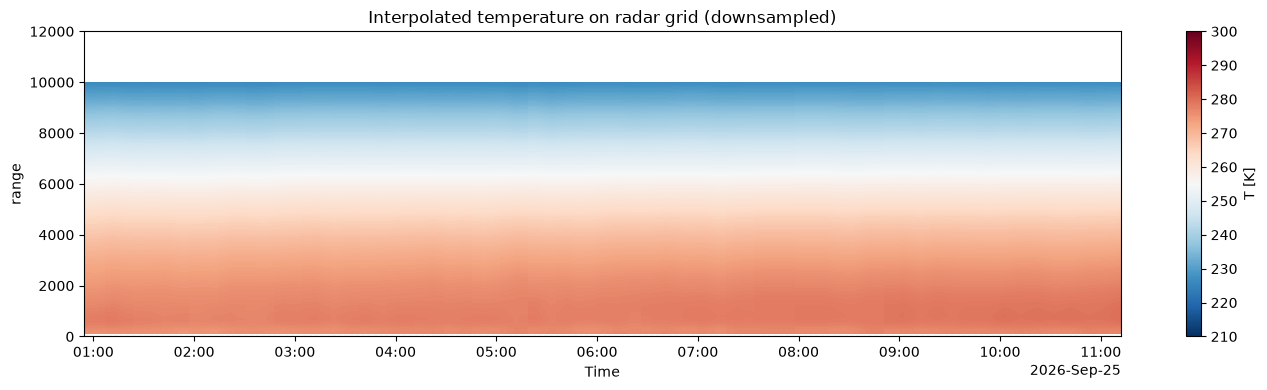

In [48]:

fig, ax = plt.subplots(1, 1, figsize=(14, 4))

T_on_range.isel(Time=slice(0, None, 5)).plot(
    x="Time",
    y="range",
    ax=ax,
    cmap="RdBu_r",
    vmin=210,
    vmax=300,
    cbar_kwargs={"label": "T [K]"},
)

ax.axhline(0, ls="--", c="k", lw=0.8, alpha=0.5)
ax.set_ylim(0, 12000)
ax.set_title("Interpolated temperature on radar grid (downsampled)")

plt.tight_layout()
plt.show()


HUMIDITY FOR DATA SAVING

The AH Profile Values are interpolated onto the Range grid. First we have to get the altitudes for the Humidity Profile in HAlts, because Humidity Profile AHProf only has Indices 1,2,3,.... in HAlt.       Afterwards AH_Prof uses HAlts Altitudes and then the Values are interpolated onto the range grid

In [49]:
print(AH_on_range)
print(AH_on_range.dims)
print(AH_on_range.shape)

<xarray.DataArray 'AH_cloud' (Time: 17229, range: 442)> Size: 61MB
array([[7.08792781, 7.06128515, 7.03472758, ...,        nan,        nan,
               nan],
       [7.0878913 , 7.06125058, 7.03469498, ...,        nan,        nan,
               nan],
       [7.08785478, 7.06121601, 7.03466237, ...,        nan,        nan,
               nan],
       ...,
       [8.44829549, 8.42386761, 8.39973763, ...,        nan,        nan,
               nan],
       [8.44828053, 8.42384581, 8.39970901, ...,        nan,        nan,
               nan],
       [8.44826542, 8.42382381, 8.39968013, ...,        nan,        nan,
               nan]], shape=(17229, 442))
Coordinates:
  * Time     (Time) datetime64[ns] 138kB 2026-09-25T00:54:34.314000010 ... 20...
  * range    (range) float64 4kB 104.3 119.3 134.2 ... 1.094e+04 1.097e+04
Attributes:
    units:    g m-3
('Time', 'range')
(17229, 442)


LWP FOR DATA SAVING

In [50]:
# ---------- step 30: LWP ----------
# W radar LWP in g m-2. Which name exists depends on the loader you used in step 3:
# 'LWP' (old-name loader, already converted) or Cloudnet's 'lwp' in kg m-2 (CloudnetPy rpg.py convert_units).
lwp_w = ds_w["LWP"] if "LWP" in ds_w else ds_w["lwp"] * 1000.0
lwp = w_at_common_times(lwp_w).rename("LWP")
lwp.attrs["units"] = "g m-2"


PRESSURE FOR DATA SAVING

In [51]:
# ---------- step 31: surface pressure (only needed with the MWR option) ----------
surface_pressure_w = ds_w["SurfPres"] if "SurfPres" in ds_w else ds_w["air_pressure"] / 100.0   # Pa -> hPa
print("valid fraction of surface pressure:", float(surface_pressure_w.notnull().mean()))


valid fraction of surface pressure: 1.0


exponential atmosphere (constant scale height)

In [52]:
# Surface pressure (hPa)
surface_pressure = w_at_common_times(surface_pressure_w).values

# Radar heights (m)
radar_range = ze_w_c["range"].values

# Create an empty array for the pressure profile
pressure_profile = np.zeros((len(ze_w_c.Time), len(ze_w_c.range)))

# Atmospheric scale height (m)
scale_height = 8000.0     #H=R_d*​T/g​       8000 for T= 273K ; At 288 K --> H=8427 m     ; At 250 K --> H=7310 m          Couple % difference and more in higher regions of clouds. In lower just a few % difference.

# Loop over all time steps
for t in range(len(surface_pressure)):

    # Surface pressure at this time
    p0 = surface_pressure[t]

    # Loop over all radar gates
    for r in range(len(radar_range)):

        height = radar_range[r]

        pressure_profile[t, r] = p0 * np.exp(-height / scale_height)

# Convert to xarray
P_cloud = xr.DataArray(
    pressure_profile,
    coords={
        "Time": ze_w_c["Time"],
        "range": ze_w_c["range"]
    },
    dims=("Time", "range"),
    name="P_cloud"
)

P_cloud.attrs["units"] = "hPa"
P_cloud.attrs["long_name"] = "Pressure profile"

In [53]:
print(P_cloud)
print(P_cloud.dims)
print(P_cloud.shape)

<xarray.DataArray 'P_cloud' (Time: 17229, range: 442)> Size: 61MB
array([[973.1243429 , 971.31281009, 969.50464956, ..., 252.32976898,
        251.25743477, 250.18962714],
       [973.1243429 , 971.31281009, 969.50464956, ..., 252.32976898,
        251.25743477, 250.18962714],
       [973.1243429 , 971.31281009, 969.50464956, ..., 252.32976898,
        251.25743477, 250.18962714],
       ...,
       [970.45931851, 968.65274682, 966.84953817, ..., 251.63873192,
        250.56933443, 249.50445113],
       [970.45931851, 968.65274682, 966.84953817, ..., 251.63873192,
        250.56933443, 249.50445113],
       [970.45931851, 968.65274682, 966.84953817, ..., 251.63873192,
        250.56933443, 249.50445113]], shape=(17229, 442))
Coordinates:
  * Time     (Time) datetime64[ns] 138kB 2026-09-25T00:54:34.314000010 ... 20...
  * range    (range) float64 4kB 104.3 119.3 134.2 ... 1.094e+04 1.097e+04
Attributes:
    units:      hPa
    long_name:  Pressure profile
('Time', 'range')
(17229, 442)


Hypsometric Equation

In [54]:
# # Physical constants
# g = 9.80665          # m/s²
# R_d = 287.05         # J/(kg K)

# # Surface pressure (hPa)
# surface_pressure = ds_w["SurfPres"]

# # Radar heights (m)
# radar_range = ze_w_c["range"].values

# # Temperature on the radar grid (K)
# temperature = T_on_range.values

# # Create an empty array
# pressure_profile = np.zeros(
#     temperature.shape,
#     dtype=np.float32
# )

# # Loop over every radar profile
# for t in range(len(surface_pressure)):

#     # Pressure at the first radar gate
#     pressure_profile[t, 0] = surface_pressure.values[t]

#     # Loop upward through the atmosphere
#     for r in range(1, len(radar_range)):

#         # Height difference between two radar gates
#         dz = radar_range[r] - radar_range[r - 1]

#         # Mean temperature between the two gates
#         T_mean = 0.5 * (
#             temperature[t, r] +
#             temperature[t, r - 1]
#         )

#         # Pressure at the current gate
#         pressure_previous = pressure_profile[t, r - 1]

#         # Hypsometric equation
#         pressure_profile[t, r] = (
#             pressure_previous *
#             np.exp(-g * dz / (R_d * T_mean))
#         )

# # Convert to xarray
# P_cloud = xr.DataArray(
#     pressure_profile,
#     coords={
#         "Time": ze_w_c["Time"],
#         "range": ze_w_c["range"]
#     },
#     dims=("Time", "range"),
#     name="P_cloud"
# )

# P_cloud.attrs["units"] = "hPa"
# P_cloud.attrs["long_name"] = "Pressure profile"

Mean Doppler Velocities

In [55]:
print(f"After alignment: W={MeanVel_W_c.shape}, Ka={MeanVel_Ka_c.shape}")
assert MeanVel_W_c.shape == MeanVel_Ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

After alignment: W=(17229, 442), Ka=(17229, 442)
✅ Aligned on common (time, range) grid


==================================================================================================================================================

SAVE DATA

==================================================================================================================================================

In [56]:
# =====================================================================================
# CELL 47 - SAVE   (the SLv/SLh lines are gone; method recorded in the file)
# =====================================================================================
ds_out = xr.Dataset(
    {
        "MeanVel_W":  MeanVel_W_c.rename("MeanVel_W"),
        "MeanVel_Ka": MeanVel_Ka_c.rename("MeanVel_Ka"),
        "Ze_W":       ze_w_c.rename("Ze_W"),
        "Ze_Ka":      ze_ka_c.rename("Ze_Ka"),
        "T_cloud":    T_on_range,
        "AH_cloud":   AH_on_range,
        "P_cloud":    P_cloud,
        "LWP":        lwp,
        "program": ds_ka["program"].sel(Time=common_times).load(),
    },
    attrs={
        "description": "Ka and W on a common time/range grid + T, AH, P for the LWC retrieval",
        "date": "20260925",
        "site": "Pallasjarvi",
        "range_matching": RANGE_MATCHING_METHOD,
        "source": f"RPG LV1 raw files, programmes {KEEP_PROGRAMS}; T/AH from HATPRO; P barometric",
        "Ze_units": "dBZ",
        "P_units": "hPa",
        "MeanVel_units": "m/s",
        "LWP_units": "g m-2",
        "created_by": "02_align.ipynb",
    },
)
# xarray silently merges different time/range axes into one bigger axis; this stops that.
assert ds_out.sizes["Time"] == common_times.size and ds_out.sizes["range"] == common_range.size, ds_out.sizes
out_path = Path(f"../data/processed/{Processed_Dataset}/aligned_LWP2.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)
ds_out.to_netcdf(out_path)
print(f"Saved → {out_path}")
print(ds_out)


Saved → ..\data\processed\20260925_pallas_raw_P02_P07_CLARA\aligned_LWP2.nc
<xarray.Dataset> Size: 427MB
Dimensions:     (Time: 17229, range: 442)
Coordinates:
  * Time        (Time) datetime64[ns] 138kB 2026-09-25T00:54:34.314000010 ......
  * range       (range) float64 4kB 104.3 119.3 134.2 ... 1.094e+04 1.097e+04
Data variables:
    MeanVel_W   (Time, range) float64 61MB 0.6093 0.2883 0.118 ... nan nan nan
    MeanVel_Ka  (Time, range) float64 61MB 0.6096 0.2916 0.1132 ... nan nan nan
    Ze_W        (Time, range) float64 61MB -33.68 -30.59 -28.2 ... nan nan nan
    Ze_Ka       (Time, range) float64 61MB -31.21 -28.8 -27.1 ... nan nan nan
    T_cloud     (Time, range) float64 61MB 275.9 275.9 275.9 ... nan nan nan
    AH_cloud    (Time, range) float64 61MB 7.088 7.061 7.035 ... nan nan nan
    P_cloud     (Time, range) float64 61MB 973.1 971.3 969.5 ... 250.6 249.5
    LWP         (Time) float32 69kB dask.array<chunksize=(526,), meta=np.ndarray>
    program     (Time) <U3 207kB 'P0

In [57]:
# Check if LWP exists in Ka dataset
print("Ka variables:")
print(ds_ka.data_vars)

print("\nW variables:")
print(ds_w.data_vars)

Ka variables:
Data variables:
    Freq        (Time) float32 69kB 35.0 35.0 35.0 35.0 ... 35.0 35.0 35.0 35.0
    DoppLen     (Time, Chirp) int32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    AvgNum      (Time, Chirp) int32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    SeqIntTime  (Time, Chirp) float32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    RangeRes    (Time, Chirp) float32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    MaxVel      (Time, Chirp) float32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    Timems      (Time) int32 69kB dask.array<chunksize=(526,), meta=np.ndarray>
    SurfPres    (Time) float32 69kB dask.array<chunksize=(526,), meta=np.ndarray>
    LWP         (Time) float32 69kB dask.array<chunksize=(526,), meta=np.ndarray>
    C1ZE        (Time, C1Range) float32 5MB dask.array<chunksize=(526, 74), meta=np.ndarray>
    C1MeanVel   (Time, C1Range) float32 5MB dask.array<chunksize=(526, 74), meta=np.ndarray>
    

Trying Things

## Instrument table and Chirp Table

In [58]:
ds_w

<xarray.Dataset> Size: 63MB
Dimensions:     (Time: 17229, Chirp: 3, C1Range: 74, C2Range: 134, C3Range: 234)
Coordinates:
  * Time        (Time) datetime64[ns] 138kB 2026-09-25T00:54:34.314000010 ......
  * C1Range     (C1Range) float32 296B 104.3 119.3 134.2 ... 1.178e+03 1.193e+03
  * C2Range     (C2Range) float32 536B 1.202e+03 1.215e+03 ... 2.997e+03
  * C3Range     (C3Range) float32 936B 3.032e+03 3.066e+03 ... 1.097e+04
Dimensions without coordinates: Chirp
Data variables: (12/16)
    Freq        (Time) float32 69kB 94.0 94.0 94.0 94.0 ... 94.0 94.0 94.0 94.0
    DoppLen     (Time, Chirp) int32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    AvgNum      (Time, Chirp) int32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    SeqIntTime  (Time, Chirp) float32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    RangeRes    (Time, Chirp) float32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    MaxVel      (Time, Chirp) float32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    ...          ...
    C1MeanVel   (Time, C1Range) float32 5MB dask.array<chunksize=(526, 74), meta=np.ndarray>
    C2ZE        (Time, C2Range) float32 9MB dask.array<chunksize=(526, 134), meta=np.ndarray>
    C2MeanVel   (Time, C2Range) float32 9MB dask.array<chunksize=(526, 134), meta=np.ndarray>
    C3ZE        (Time, C3Range) float32 16MB dask.array<chunksize=(526, 234), meta=np.ndarray>
    C3MeanVel   (Time, C3Range) float32 16MB dask.array<chunksize=(526, 234), meta=np.ndarray>
    program     (Time) <U3 207kB 'P02' 'P02' 'P02' 'P02' ... 'P07' 'P07' 'P07'
Attributes:
    Program name:  Pallas high
    Customer:      DELFT3_W

In [59]:
ds_ka

<xarray.Dataset> Size: 63MB
Dimensions:     (Time: 17229, Chirp: 3, C1Range: 74, C2Range: 134, C3Range: 234)
Coordinates:
  * Time        (Time) datetime64[ns] 138kB 2026-09-25T00:54:34.314000010 ......
  * C1Range     (C1Range) float32 296B 104.3 119.3 134.2 ... 1.178e+03 1.193e+03
  * C2Range     (C2Range) float32 536B 1.202e+03 1.215e+03 ... 2.997e+03
  * C3Range     (C3Range) float32 936B 3.032e+03 3.066e+03 ... 1.097e+04
Dimensions without coordinates: Chirp
Data variables: (12/16)
    Freq        (Time) float32 69kB 35.0 35.0 35.0 35.0 ... 35.0 35.0 35.0 35.0
    DoppLen     (Time, Chirp) int32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    AvgNum      (Time, Chirp) int32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    SeqIntTime  (Time, Chirp) float32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    RangeRes    (Time, Chirp) float32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    MaxVel      (Time, Chirp) float32 207kB dask.array<chunksize=(526, 3), meta=np.ndarray>
    ...          ...
    C1MeanVel   (Time, C1Range) float32 5MB dask.array<chunksize=(526, 74), meta=np.ndarray>
    C2ZE        (Time, C2Range) float32 9MB dask.array<chunksize=(526, 134), meta=np.ndarray>
    C2MeanVel   (Time, C2Range) float32 9MB dask.array<chunksize=(526, 134), meta=np.ndarray>
    C3ZE        (Time, C3Range) float32 16MB dask.array<chunksize=(526, 234), meta=np.ndarray>
    C3MeanVel   (Time, C3Range) float32 16MB dask.array<chunksize=(526, 234), meta=np.ndarray>
    program     (Time) <U3 207kB 'P02' 'P02' 'P02' 'P02' ... 'P07' 'P07' 'P07'
Attributes:
    Program name:  Pallas high
    Customer:      DELFT3-K

In [60]:
ds_out

<xarray.Dataset> Size: 427MB
Dimensions:     (Time: 17229, range: 442)
Coordinates:
  * Time        (Time) datetime64[ns] 138kB 2026-09-25T00:54:34.314000010 ......
  * range       (range) float64 4kB 104.3 119.3 134.2 ... 1.094e+04 1.097e+04
Data variables:
    MeanVel_W   (Time, range) float64 61MB 0.6093 0.2883 0.118 ... nan nan nan
    MeanVel_Ka  (Time, range) float64 61MB 0.6096 0.2916 0.1132 ... nan nan nan
    Ze_W        (Time, range) float64 61MB -33.68 -30.59 -28.2 ... nan nan nan
    Ze_Ka       (Time, range) float64 61MB -31.21 -28.8 -27.1 ... nan nan nan
    T_cloud     (Time, range) float64 61MB 275.9 275.9 275.9 ... nan nan nan
    AH_cloud    (Time, range) float64 61MB 7.088 7.061 7.035 ... nan nan nan
    P_cloud     (Time, range) float64 61MB 973.1 971.3 969.5 ... 250.6 249.5
    LWP         (Time) float32 69kB dask.array<chunksize=(526,), meta=np.ndarray>
    program     (Time) <U3 207kB 'P02' 'P02' 'P02' 'P02' ... 'P07' 'P07' 'P07'
Attributes:
    description:     Ka and W on a common time/range grid + T, AH, P for the ...
    date:            20260925
    site:            Pallasjarvi
    range_matching:  interpolation
    source:          RPG LV1 raw files, programmes ('P02', 'P07'); T/AH from ...
    Ze_units:        dBZ
    P_units:         hPa
    MeanVel_units:   m/s
    LWP_units:       g m-2
    created_by:      02_align.ipynb